In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
# Excelファイルの読み込んでデータフレームに格納
df = pd.read_csv('pregnant mouse ELISA.csv')  # インデックスのカラムを指定
df


,concentration,O.D.
0,5000.0,2.297
1,2500.0,2.264
2,1250.0,1.538
3,625.0,1.296
4,312.0,1.115
5,156.0,0.880
6,78.0,0.495
7,0.0,0.106
8,1000.0,1.619
9,500.0,0.899


   concentration   O.D.
0         5000.0  2.297
1         2500.0  2.264
2         1250.0  1.538
3          625.0  1.296
4          312.0  1.115


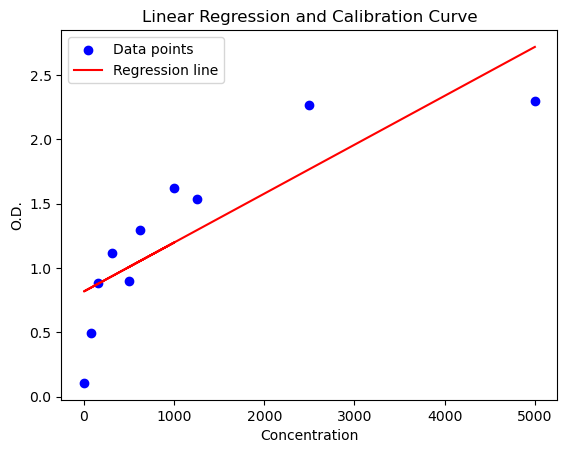

Regression equation: O.D. = 0.00 * Concentration + 0.82


In [13]:
# NaN 値を含む行を削除
df = df.dropna()

# データの確認
print(df.head())

# 縦軸 (O.D.) と横軸 (concentration) のデータを取得
x = df['concentration'].values.reshape(-1, 1)
y = df['O.D.'].values

# 単回帰モデルの作成
model = LinearRegression()
model.fit(x, y)

# 回帰係数と切片を取得
slope = model.coef_[0]
intercept = model.intercept_

# 回帰直線を描画するためのy値を計算
y_pred = model.predict(x)

# プロットの作成
plt.scatter(x, y, color='blue', label='Data points')
plt.plot(x, y_pred, color='red', label='Regression line')
plt.xlabel('Concentration')
plt.ylabel('O.D.')
plt.title('Linear Regression and Calibration Curve')
plt.legend()
plt.show()

# 検量線の方程式を表示
print(f'Regression equation: O.D. = {slope:.2f} * Concentration + {intercept:.2f}')
# サンプルのO.D.から濃度を求める関数
def calculate_concentration(sample_od):
    global slope, intercept
    sample_concentration = (sample_od - intercept) / slope
    print(f'The concentration corresponding to O.D. = {sample_od} is {sample_concentration:.2f}')
    return sample_concentration

# 例として回帰分析を実行し、サンプルの濃度を計算
perform_regression()
sample_od = 0.6  # ここに実際のO.D.の値を代入
calculate_concentration(sample_od)


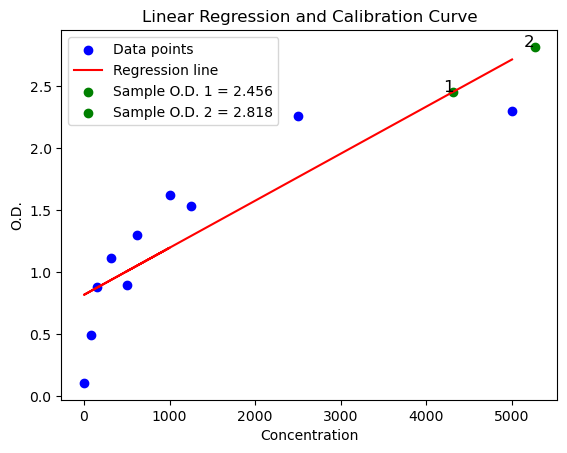

Regression equation: O.D. = 3.8e-04 * Concentration + 0.82
The concentration corresponding to O.D. 1 = 2.456 is 4314
The concentration corresponding to O.D. 2 = 2.818 is 5266


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


# NaN 値を含む行を削除
df = df.dropna()



# 縦軸 (O.D.) と横軸 (concentration) のデータを取得
x = df['concentration'].values.reshape(-1, 1)
y = df['O.D.'].values

# 単回帰モデルの作成
model = LinearRegression()
model.fit(x, y)

# 回帰係数と切片を取得
slope = model.coef_[0]
intercept = model.intercept_

# 回帰直線を描画するためのy値を計算
y_pred = model.predict(x)

# プロットの作成
plt.scatter(x, y, color='blue', label='Data points')
plt.plot(x, y_pred, color='red', label='Regression line')

# サンプルのO.D.のリスト
sample_ods = [2.456, 2.818]  # ここに実際のO.D.の値を代入

# 各サンプルのO.D.に対して濃度を計算し、プロット
for i, sample_od in enumerate(sample_ods, start=1):
    sample_concentration = (sample_od - intercept) / slope
    plt.scatter(sample_concentration, sample_od, color='green', label=f'Sample O.D. {i} = {sample_od}')
    plt.text(sample_concentration, sample_od, f'{i}', fontsize=12, ha='right')
    

plt.xlabel('Concentration')
plt.ylabel('O.D.')
plt.title('Linear Regression and Calibration Curve')
plt.legend()
plt.savefig('calibration_curve.svg', format='svg')
plt.show()

# 検量線の方程式を表示
print(f'Regression equation: O.D. = {slope:.1e} * Concentration + {intercept:.2f}')

# サンプルのO.D.から濃度を求める関数
def calculate_concentration(sample_od, index):
    global slope, intercept
    sample_concentration = (sample_od - intercept) / slope
    print(f'The concentration corresponding to O.D. {index} = {sample_od} is {sample_concentration:.0f}')
    return sample_concentration

# 例としてサンプルの濃度を計算
for i, sample_od in enumerate(sample_ods, start=1):
    calculate_concentration(sample_od, i)

**Regression equation: O.D. = 3.8e-04 * Concentration + 0.82**- 
The concentration corresponding to O.D. 1 = 2.456 is 4343- 
The concentration corresponding to O.D. 2 = 2.818 is 5245645


**Regression equation: O.D. = 3.8×10^{-4} × Concentration + 0.82**
- 1. The concentration corresponding to O.D. 1 = 2.456 is 43-
2. The concentration corresponding to O.D. 2 = 2.818 is 566
